# Forward propagation e backpropagation

## 1. A tarefa e a rede

**Tarefa: classificação em 2 classes.** A rede recebe um ponto $x = (x_1, x_2)$ e devolve $s = (s_1, s_2)$, a probabilidade de $x$ ser da classe 1 ou da classe 2. O exemplo usado é $x = (0.3,\ 0.5)$, da classe 1, então o rótulo em one-hot é $y = (1, 0)$.

**Loss por máxima verossimilhança:**

1. a saída é tratada como uma distribuição categórica sobre as 2 classes;
2. a rede prevê os parâmetros dessa distribuição com a softmax, $s = \text{softmax}(z^{(3)})$, que dá números positivos que somam 1;
3. a loss é o negativo do log da verossimilhança do rótulo certo: $L = -\log s_{\text{classe certa}} = -\sum_i y_i \log s_i$ (cross-entropy).

**Rede:** 2 entradas, 2 camadas hidden com 3 neurônios cada e 2 saídas.

- $w^{(c)}_{j,k}$: peso da conexão que sai do neurônio $k$ da camada $c-1$ e entra no neurônio $j$ da camada $c$; a entrada é a camada 0, $a^{(0)} = x$
- $z^{(c)}_j = \sum_k w^{(c)}_{j,k}\, a^{(c-1)}_k + b^{(c)}_j$
- camadas hidden ($c = 1, 2$): $a^{(c)}_j = f(z^{(c)}_j)$, com a sigmoide $f(z) = \dfrac{1}{1 + e^{-z}}$ e $f'(z) = f(z)\,\big(1 - f(z)\big)$
- saída ($c = 3$): $s_j = \dfrac{e^{z^{(3)}_j}}{\sum_k e^{z^{(3)}_k}}$

A rede está toda neste notebook, só com NumPy. O `visualizacao.py` só desenha e formata as contas.

In [1]:
import numpy as np

import visualizacao as vis   # desenhos e contas formatadas

np.set_printoptions(precision=4, suppress=True)

In [2]:
x = np.array([0.3, 0.5])   # entrada
y = np.array([1.0, 0.0])   # classe 1 (one-hot)

In [3]:
# W[c][j, k] = peso que sai do neurônio k da camada c-1 e chega no neurônio j da camada c
W = {
    1: np.array([[0.1, 0.2],
                 [0.1, 0.8],
                 [0.5, 0.9]]),
    2: np.array([[0.3, 0.4, 0.4],
                 [0.7, 0.4, 0.4],
                 [0.6, 0.5, 0.3]]),
    3: np.array([[0.2, 0.2, 0.6],
                 [0.7, 0.3, 0.8]]),
}

In [4]:
b = {
    1: np.array([0.2, 0.4, 0.6]),
    2: np.array([0.4, 0.3, 0.7]),
    3: np.array([0.5, 0.6]),
}

C = 3   # número de camadas (sem contar a entrada)

In [5]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def sigmoide_derivada(z):
    s = sigmoide(z)
    return s * (1 - s)


def softmax(z):
    # subtrai o máximo pra não dar overflow no exp
    e = np.exp(z - np.max(z))
    return e / np.sum(e)


def loss(s, y):
    # cross-entropy
    return -np.sum(y * np.log(s))

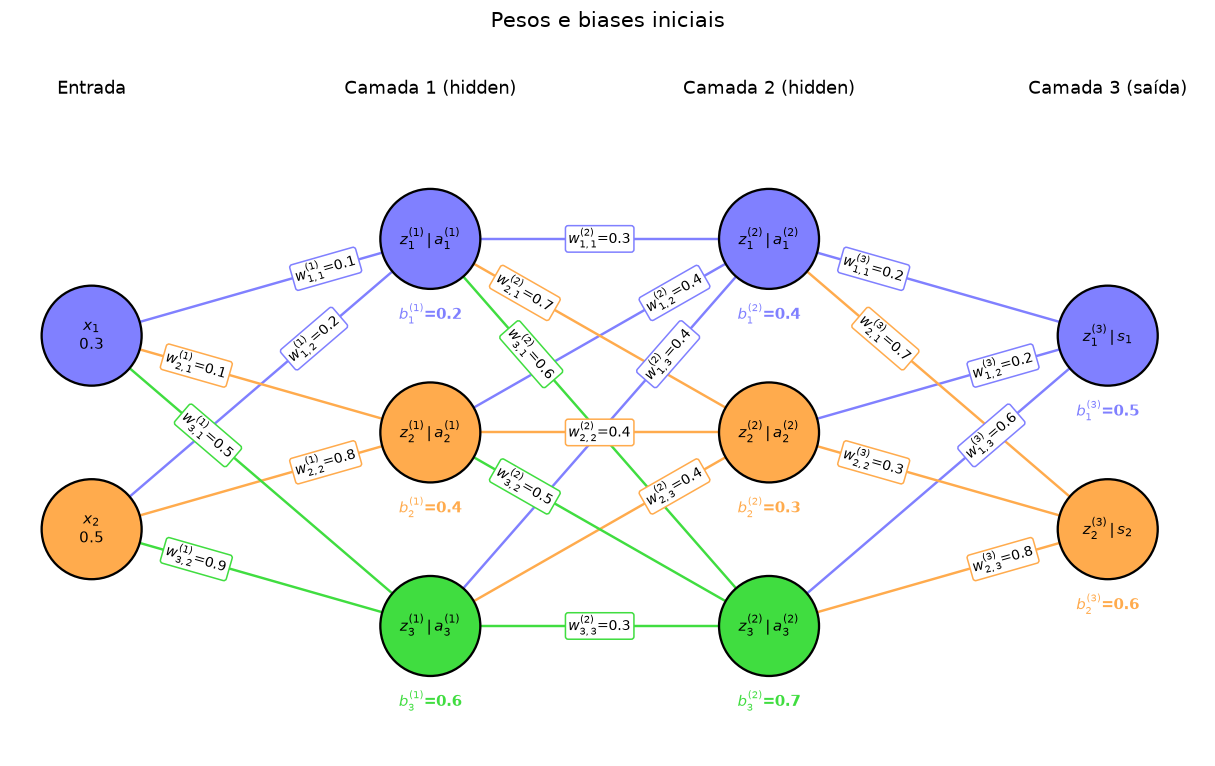

In [6]:
vis.desenhar_parametros(x, W, b)

## 2. Forward pass

$$z^{(c)} = W^{(c)} a^{(c-1)} + b^{(c)} \qquad\qquad a^{(c)} = f\big(z^{(c)}\big)\ \text{ nas hidden} \qquad\qquad s = \text{softmax}\big(z^{(3)}\big)\ \text{ na saída}$$

In [7]:
z = {}
a = {0: x}   # camada 0 é a entrada

In [8]:
# camada 1 (sigmoide)
z[1] = W[1] @ a[0] + b[1]
a[1] = sigmoide(z[1])

vis.conta_forward(1, W, b, z, a)

- $z^{(1)}_1 = 0.1 \cdot 0.3000 + 0.2 \cdot 0.5000 + 0.2 = 0.3300 \quad\Rightarrow\quad a^{(1)}_1 = f(0.3300) = 0.5818$
- $z^{(1)}_2 = 0.1 \cdot 0.3000 + 0.8 \cdot 0.5000 + 0.4 = 0.8300 \quad\Rightarrow\quad a^{(1)}_2 = f(0.8300) = 0.6964$
- $z^{(1)}_3 = 0.5 \cdot 0.3000 + 0.9 \cdot 0.5000 + 0.6 = 1.2000 \quad\Rightarrow\quad a^{(1)}_3 = f(1.2000) = 0.7685$

In [9]:
# camada 2 (sigmoide)
z[2] = W[2] @ a[1] + b[2]
a[2] = sigmoide(z[2])

vis.conta_forward(2, W, b, z, a)

- $z^{(2)}_1 = 0.3 \cdot 0.5818 + 0.4 \cdot 0.6964 + 0.4 \cdot 0.7685 + 0.4 = 1.1605 \quad\Rightarrow\quad a^{(2)}_1 = f(1.1605) = 0.7614$
- $z^{(2)}_2 = 0.7 \cdot 0.5818 + 0.4 \cdot 0.6964 + 0.4 \cdot 0.7685 + 0.3 = 1.2932 \quad\Rightarrow\quad a^{(2)}_2 = f(1.2932) = 0.7847$
- $z^{(2)}_3 = 0.6 \cdot 0.5818 + 0.5 \cdot 0.6964 + 0.3 \cdot 0.7685 + 0.7 = 1.6278 \quad\Rightarrow\quad a^{(2)}_3 = f(1.6278) = 0.8359$

In [10]:
# camada 3 (softmax)
z[3] = W[3] @ a[2] + b[3]
a[3] = softmax(z[3])

vis.conta_forward(3, W, b, z, a)

- $z^{(3)}_1 = 0.2 \cdot 0.7614 + 0.2 \cdot 0.7847 + 0.6 \cdot 0.8359 + 0.5 = 1.3107 \quad\Rightarrow\quad s_1 = \frac{e^{1.3107}}{e^{1.3107} + e^{2.0371}} = 0.3260$
- $z^{(3)}_2 = 0.7 \cdot 0.7614 + 0.3 \cdot 0.7847 + 0.8 \cdot 0.8359 + 0.6 = 2.0371 \quad\Rightarrow\quad s_2 = \frac{e^{2.0371}}{e^{1.3107} + e^{2.0371}} = 0.6740$

In [11]:
s = a[3]
L = loss(s, y)

vis.conta_loss(s, y, L)

$s_1 = 0.3260$, $s_2 = 0.6740$ (somam 1.0000); classe prevista: **2**, classe certa: **1**

$L = -(y_1 \log s_1 + y_2 \log s_2) = -(1 \cdot \log 0.3260 + 0 \cdot \log 0.6740) = 1.1209$

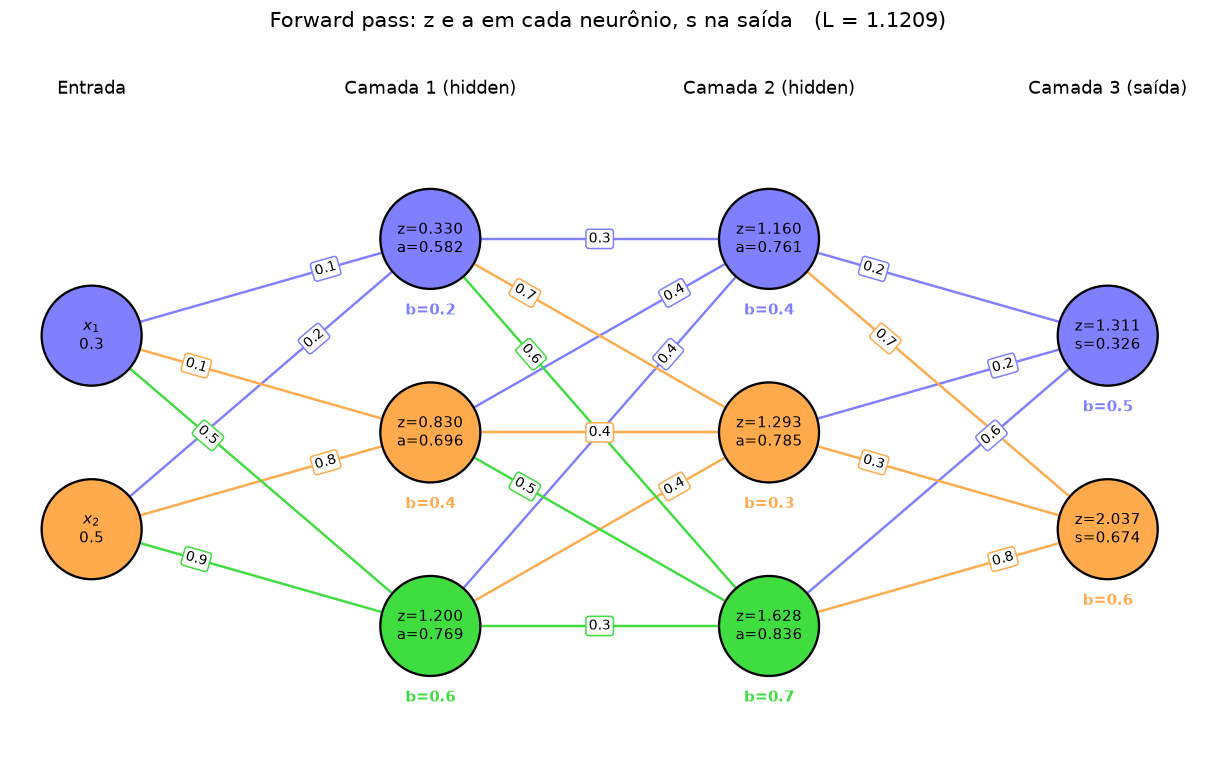

In [12]:
vis.desenhar_forward(x, W, b, z, a, L)

In [13]:
# o mesmo forward num laço, pra usar no treino
def forward(W, b, x):
    a = {0: x}
    z = {}
    for c in range(1, C + 1):
        z[c] = W[c] @ a[c - 1] + b[c]
        a[c] = softmax(z[c]) if c == C else sigmoide(z[c])
    return z, a


z_teste, a_teste = forward(W, b, x)
print('igual ao feito à mão?', all(np.allclose(a_teste[c], a[c]) for c in range(C + 1)))

igual ao feito à mão? True


## 3. Backpropagation

| Passo | Fórmula |
|---|---|
| 1 (só na saída) | $\dfrac{\partial L}{\partial s_i} = -\dfrac{y_i}{s_i}$ |
| 2, hidden | $\dfrac{\partial L}{\partial z^{(c)}_i} = \dfrac{\partial L}{\partial a^{(c)}_i} \cdot f'\big(z^{(c)}_i\big)$ |
| 2, saída | $\dfrac{\partial L}{\partial z^{(C)}_i} = \displaystyle\sum_{j} \dfrac{\partial L}{\partial s_j} \cdot \dfrac{\partial s_j}{\partial z^{(C)}_i}$ |
| 3 | $\dfrac{\partial L}{\partial b^{(c)}_i} = \dfrac{\partial L}{\partial z^{(c)}_i}$ |
| 4 | $\dfrac{\partial L}{\partial w^{(c)}_{i,j}} = \dfrac{\partial L}{\partial z^{(c)}_i} \cdot a^{(c-1)}_j$ |
| 5 ($c \neq 1$) | $\dfrac{\partial L}{\partial a^{(c-1)}_i} = \displaystyle\sum_{j=1}^{n_c} \dfrac{\partial L}{\partial z^{(c)}_j} \cdot w^{(c)}_{j,i}$ |

### Passo 2 na saída

Nas camadas hidden, cada $a_i$ depende só do seu $z_i$, então o passo 2 é feito neurônio por neurônio. Na softmax isso não vale: cada $s_j$ depende de **todos** os $z$, porque o denominador soma todos eles. Por isso $\partial L / \partial z_i$ junta uma parcela de cada $s_j$, e as derivadas $\partial s_j / \partial z_i$ formam uma matriz, a jacobiana da softmax:

$$J_{j,i} = \frac{\partial s_j}{\partial z_i} = s_j\,(\delta_{ij} - s_i) \qquad (\delta_{ij} = 1 \text{ se } i = j, \text{ senão } 0) \qquad\qquad \frac{\partial L}{\partial z^{(C)}} = J^T \, \frac{\partial L}{\partial s}$$

In [14]:
dL_da, dL_dz, grad_b, grad_W = {}, {}, {}, {}

### Camada 3

In [15]:
# passo 1: derivada da cross-entropy em relação a cada s
dL_da[3] = -y / s

vis.conta_passo1(s, y, dL_da[3])

- $\frac{\partial L}{\partial s_1} = -\frac{y_1}{s_1} = -\frac{1}{0.3260} = -3.0675$
- $\frac{\partial L}{\partial s_2} = -\frac{y_2}{s_2} = -\frac{0}{0.6740} = 0.0000$

In [16]:
# passo 2 na saída: jacobiana da softmax, J[j, i] = ds_j/dz_i
J = np.diag(s) - np.outer(s, s)
dL_dz[3] = J.T @ dL_da[3]

vis.conta_passo2_softmax(J, dL_da[3], dL_dz[3])

$$J = \begin{pmatrix} 0.2197 & -0.2197 \\ -0.2197 & 0.2197 \end{pmatrix}$$

- $\frac{\partial L}{\partial z^{(3)}_1} = \sum_j \frac{\partial L}{\partial s_j} \, J_{j,1} = (-3.0675) \cdot (0.2197) + (0.0000) \cdot (-0.2197) = -0.6740$
- $\frac{\partial L}{\partial z^{(3)}_2} = \sum_j \frac{\partial L}{\partial s_j} \, J_{j,2} = (-3.0675) \cdot (-0.2197) + (0.0000) \cdot (0.2197) = 0.6740$

In [17]:
# passo 3
grad_b[3] = dL_dz[3]

vis.conta_passo3(3, grad_b[3])

- $\frac{\partial L}{\partial b^{(3)}_1} = \frac{\partial L}{\partial z^{(3)}_1} = -0.6740$
- $\frac{\partial L}{\partial b^{(3)}_2} = \frac{\partial L}{\partial z^{(3)}_2} = 0.6740$

In [18]:
# passo 4
grad_W[3] = np.outer(dL_dz[3], a[2])

vis.conta_passo4(3, dL_dz[3], a[2], grad_W[3])

- $\frac{\partial L}{\partial w^{(3)}_{1,1}} = \frac{\partial L}{\partial z^{(3)}_1} \cdot a^{(2)}_1 = -0.6740 \cdot 0.7614 = -0.5132$
- $\frac{\partial L}{\partial w^{(3)}_{1,2}} = \frac{\partial L}{\partial z^{(3)}_1} \cdot a^{(2)}_2 = -0.6740 \cdot 0.7847 = -0.5289$
- $\frac{\partial L}{\partial w^{(3)}_{1,3}} = \frac{\partial L}{\partial z^{(3)}_1} \cdot a^{(2)}_3 = -0.6740 \cdot 0.8359 = -0.5634$
- $\frac{\partial L}{\partial w^{(3)}_{2,1}} = \frac{\partial L}{\partial z^{(3)}_2} \cdot a^{(2)}_1 = 0.6740 \cdot 0.7614 = 0.5132$
- $\frac{\partial L}{\partial w^{(3)}_{2,2}} = \frac{\partial L}{\partial z^{(3)}_2} \cdot a^{(2)}_2 = 0.6740 \cdot 0.7847 = 0.5289$
- $\frac{\partial L}{\partial w^{(3)}_{2,3}} = \frac{\partial L}{\partial z^{(3)}_2} \cdot a^{(2)}_3 = 0.6740 \cdot 0.8359 = 0.5634$

In [19]:
# passo 5
dL_da[2] = W[3].T @ dL_dz[3]

vis.conta_passo5(3, dL_dz[3], W[3], dL_da[2])

- $\frac{\partial L}{\partial a^{(2)}_1} = -0.6740 \cdot 0.2 + 0.6740 \cdot 0.7 = 0.3370$
- $\frac{\partial L}{\partial a^{(2)}_2} = -0.6740 \cdot 0.2 + 0.6740 \cdot 0.3 = 0.0674$
- $\frac{\partial L}{\partial a^{(2)}_3} = -0.6740 \cdot 0.6 + 0.6740 \cdot 0.8 = 0.1348$

### Camada 2

In [20]:
# passo 2
dL_dz[2] = dL_da[2] * sigmoide_derivada(z[2])

vis.conta_passo2(2, dL_da[2], sigmoide_derivada(z[2]), dL_dz[2])

- $\frac{\partial L}{\partial z^{(2)}_1} = \frac{\partial L}{\partial a^{(2)}_1} \cdot f'(z^{(2)}_1) = 0.3370 \cdot 0.1817 = 0.0612$
- $\frac{\partial L}{\partial z^{(2)}_2} = \frac{\partial L}{\partial a^{(2)}_2} \cdot f'(z^{(2)}_2) = 0.0674 \cdot 0.1690 = 0.0114$
- $\frac{\partial L}{\partial z^{(2)}_3} = \frac{\partial L}{\partial a^{(2)}_3} \cdot f'(z^{(2)}_3) = 0.1348 \cdot 0.1372 = 0.0185$

In [21]:
# passo 3
grad_b[2] = dL_dz[2]

vis.conta_passo3(2, grad_b[2])

- $\frac{\partial L}{\partial b^{(2)}_1} = \frac{\partial L}{\partial z^{(2)}_1} = 0.0612$
- $\frac{\partial L}{\partial b^{(2)}_2} = \frac{\partial L}{\partial z^{(2)}_2} = 0.0114$
- $\frac{\partial L}{\partial b^{(2)}_3} = \frac{\partial L}{\partial z^{(2)}_3} = 0.0185$

In [22]:
# passo 4
grad_W[2] = np.outer(dL_dz[2], a[1])

vis.conta_passo4(2, dL_dz[2], a[1], grad_W[2])

- $\frac{\partial L}{\partial w^{(2)}_{1,1}} = \frac{\partial L}{\partial z^{(2)}_1} \cdot a^{(1)}_1 = 0.0612 \cdot 0.5818 = 0.0356$
- $\frac{\partial L}{\partial w^{(2)}_{1,2}} = \frac{\partial L}{\partial z^{(2)}_1} \cdot a^{(1)}_2 = 0.0612 \cdot 0.6964 = 0.0426$
- $\frac{\partial L}{\partial w^{(2)}_{1,3}} = \frac{\partial L}{\partial z^{(2)}_1} \cdot a^{(1)}_3 = 0.0612 \cdot 0.7685 = 0.0470$
- $\frac{\partial L}{\partial w^{(2)}_{2,1}} = \frac{\partial L}{\partial z^{(2)}_2} \cdot a^{(1)}_1 = 0.0114 \cdot 0.5818 = 0.0066$
- $\frac{\partial L}{\partial w^{(2)}_{2,2}} = \frac{\partial L}{\partial z^{(2)}_2} \cdot a^{(1)}_2 = 0.0114 \cdot 0.6964 = 0.0079$
- $\frac{\partial L}{\partial w^{(2)}_{2,3}} = \frac{\partial L}{\partial z^{(2)}_2} \cdot a^{(1)}_3 = 0.0114 \cdot 0.7685 = 0.0088$
- $\frac{\partial L}{\partial w^{(2)}_{3,1}} = \frac{\partial L}{\partial z^{(2)}_3} \cdot a^{(1)}_1 = 0.0185 \cdot 0.5818 = 0.0108$
- $\frac{\partial L}{\partial w^{(2)}_{3,2}} = \frac{\partial L}{\partial z^{(2)}_3} \cdot a^{(1)}_2 = 0.0185 \cdot 0.6964 = 0.0129$
- $\frac{\partial L}{\partial w^{(2)}_{3,3}} = \frac{\partial L}{\partial z^{(2)}_3} \cdot a^{(1)}_3 = 0.0185 \cdot 0.7685 = 0.0142$

In [23]:
# passo 5
dL_da[1] = W[2].T @ dL_dz[2]

vis.conta_passo5(2, dL_dz[2], W[2], dL_da[1])

- $\frac{\partial L}{\partial a^{(1)}_1} = 0.0612 \cdot 0.3 + 0.0114 \cdot 0.7 + 0.0185 \cdot 0.6 = 0.0374$
- $\frac{\partial L}{\partial a^{(1)}_2} = 0.0612 \cdot 0.4 + 0.0114 \cdot 0.4 + 0.0185 \cdot 0.5 = 0.0383$
- $\frac{\partial L}{\partial a^{(1)}_3} = 0.0612 \cdot 0.4 + 0.0114 \cdot 0.4 + 0.0185 \cdot 0.3 = 0.0346$

### Camada 1

In [24]:
# passo 2
dL_dz[1] = dL_da[1] * sigmoide_derivada(z[1])

vis.conta_passo2(1, dL_da[1], sigmoide_derivada(z[1]), dL_dz[1])

- $\frac{\partial L}{\partial z^{(1)}_1} = \frac{\partial L}{\partial a^{(1)}_1} \cdot f'(z^{(1)}_1) = 0.0374 \cdot 0.2433 = 0.0091$
- $\frac{\partial L}{\partial z^{(1)}_2} = \frac{\partial L}{\partial a^{(1)}_2} \cdot f'(z^{(1)}_2) = 0.0383 \cdot 0.2114 = 0.0081$
- $\frac{\partial L}{\partial z^{(1)}_3} = \frac{\partial L}{\partial a^{(1)}_3} \cdot f'(z^{(1)}_3) = 0.0346 \cdot 0.1779 = 0.0062$

In [25]:
# passo 3
grad_b[1] = dL_dz[1]

vis.conta_passo3(1, grad_b[1])

- $\frac{\partial L}{\partial b^{(1)}_1} = \frac{\partial L}{\partial z^{(1)}_1} = 0.0091$
- $\frac{\partial L}{\partial b^{(1)}_2} = \frac{\partial L}{\partial z^{(1)}_2} = 0.0081$
- $\frac{\partial L}{\partial b^{(1)}_3} = \frac{\partial L}{\partial z^{(1)}_3} = 0.0062$

In [26]:
# passo 4 (a camada anterior é a entrada, e aqui não tem passo 5)
grad_W[1] = np.outer(dL_dz[1], a[0])

vis.conta_passo4(1, dL_dz[1], a[0], grad_W[1])

- $\frac{\partial L}{\partial w^{(1)}_{1,1}} = \frac{\partial L}{\partial z^{(1)}_1} \cdot x_1 = 0.0091 \cdot 0.3000 = 0.0027$
- $\frac{\partial L}{\partial w^{(1)}_{1,2}} = \frac{\partial L}{\partial z^{(1)}_1} \cdot x_2 = 0.0091 \cdot 0.5000 = 0.0046$
- $\frac{\partial L}{\partial w^{(1)}_{2,1}} = \frac{\partial L}{\partial z^{(1)}_2} \cdot x_1 = 0.0081 \cdot 0.3000 = 0.0024$
- $\frac{\partial L}{\partial w^{(1)}_{2,2}} = \frac{\partial L}{\partial z^{(1)}_2} \cdot x_2 = 0.0081 \cdot 0.5000 = 0.0040$
- $\frac{\partial L}{\partial w^{(1)}_{3,1}} = \frac{\partial L}{\partial z^{(1)}_3} \cdot x_1 = 0.0062 \cdot 0.3000 = 0.0018$
- $\frac{\partial L}{\partial w^{(1)}_{3,2}} = \frac{\partial L}{\partial z^{(1)}_3} \cdot x_2 = 0.0062 \cdot 0.5000 = 0.0031$

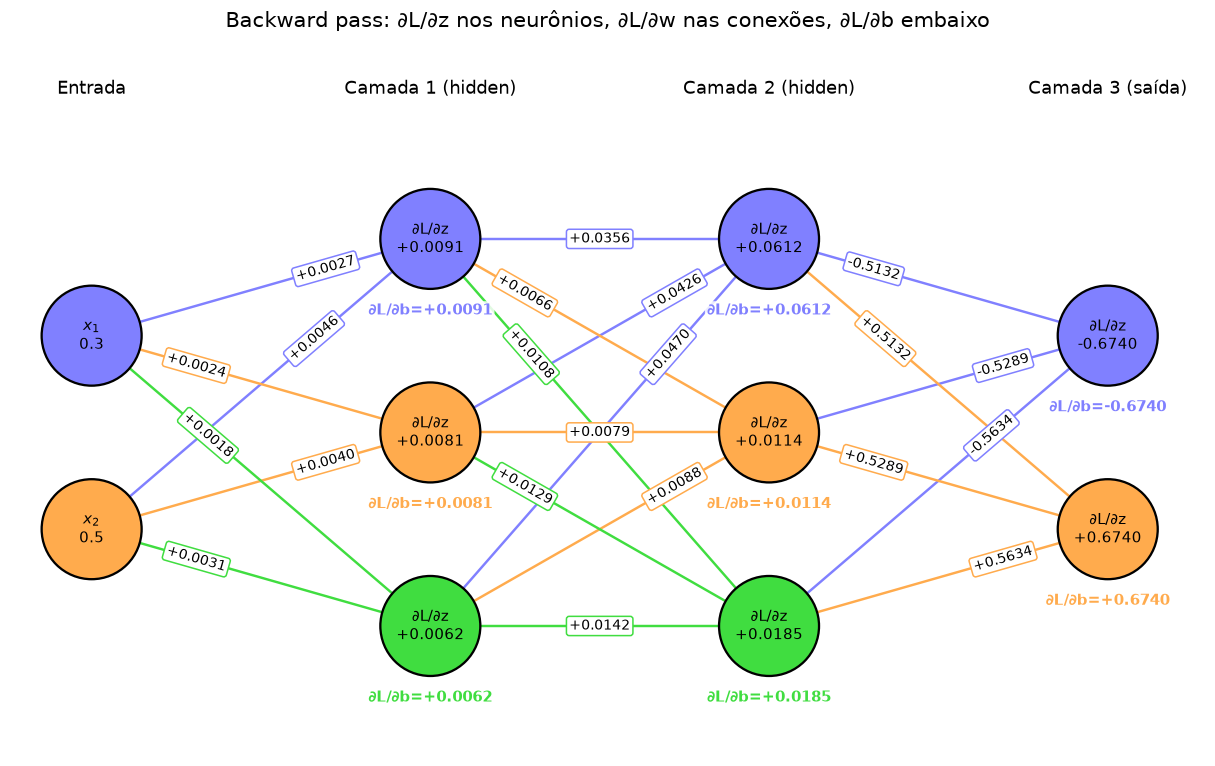

In [27]:
vis.desenhar_backward(x, W, dL_dz, grad_W, grad_b)

### Animação

Bolinhas pretas: forward, da entrada para a saída. Bolinhas vermelhas: backpropagation, da saída para a entrada.

In [28]:
# demora uns segundos pra gerar
vis.animar(x, W, b, z, a, L, dL_dz, grad_W, grad_b)

### Juntando tudo

Versão matricial dos passos:

| Passo | Fórmula |
|---|---|
| 1 | $\dfrac{\partial L}{\partial s} = -y \oslash s$ (divisão elemento a elemento) |
| 2, hidden | $\dfrac{\partial L}{\partial z^{(c)}} = \dfrac{\partial L}{\partial a^{(c)}} \odot f'\big(z^{(c)}\big)$ |
| 2, saída | $\dfrac{\partial L}{\partial z^{(C)}} = J^T \, \dfrac{\partial L}{\partial s}$ |
| 3 | $\dfrac{\partial L}{\partial b^{(c)}} = \dfrac{\partial L}{\partial z^{(c)}}$ |
| 4 | $\dfrac{\partial L}{\partial W^{(c)}} = \dfrac{\partial L}{\partial z^{(c)}} \cdot a^{(c-1)\,T}$ |
| 5 | $\dfrac{\partial L}{\partial a^{(c-1)}} = W^{(c)\,T} \cdot \dfrac{\partial L}{\partial z^{(c)}}$ |

In [29]:
# backward neurônio por neurônio, como no pseudocódigo
def backward_laco(W, b, z, a, y):
    grad_W, grad_b = {}, {}

    dL_da = {C: np.zeros(len(b[C]))}               # passo 1
    for i in range(len(b[C])):
        dL_da[C][i] = -y[i] / a[C][i]

    for c in range(C, 0, -1):
        n_c, n_ant = len(b[c]), len(a[c - 1])

        dL_dz = np.zeros(n_c)                      # passo 2
        for i in range(n_c):
            if c == C:   # softmax: soma uma parcela de cada s_j
                for j in range(n_c):
                    dL_dz[i] += dL_da[C][j] * a[C][j] * ((i == j) - a[C][i])
            else:
                dL_dz[i] = dL_da[c][i] * sigmoide_derivada(z[c][i])

        grad_b[c] = np.zeros(n_c)                  # passo 3
        for i in range(n_c):
            grad_b[c][i] = dL_dz[i]

        grad_W[c] = np.zeros((n_c, n_ant))         # passo 4
        for i in range(n_c):
            for j in range(n_ant):
                grad_W[c][i, j] = dL_dz[i] * a[c - 1][j]

        if c != 1:                                 # passo 5
            dL_da[c - 1] = np.zeros(n_ant)
            for i in range(n_ant):
                for j in range(n_c):
                    dL_da[c - 1][i] += dL_dz[j] * W[c][j, i]

    return grad_W, grad_b

In [30]:
# backward com matrizes
def backward_matricial(W, b, z, a, y):
    grad_W, grad_b = {}, {}
    dL_da = -y / a[C]                                  # passo 1
    for c in range(C, 0, -1):
        if c == C:                                     # passo 2 na saída (jacobiana)
            J = np.diag(a[C]) - np.outer(a[C], a[C])
            dL_dz = J.T @ dL_da
        else:                                          # passo 2 nas hidden (Hadamard)
            dL_dz = dL_da * sigmoide_derivada(z[c])
        grad_b[c] = dL_dz                              # passo 3
        grad_W[c] = np.outer(dL_dz, a[c - 1])          # passo 4
        if c != 1:
            dL_da = W[c].T @ dL_dz                     # passo 5
    return grad_W, grad_b

In [31]:
# compara com o que foi feito célula por célula
laco_W, laco_b = backward_laco(W, b, z, a, y)
mat_W, mat_b = backward_matricial(W, b, z, a, y)

for c in range(1, C + 1):
    dif_laco = max(np.abs(laco_W[c] - grad_W[c]).max(), np.abs(laco_b[c] - grad_b[c]).max())
    dif_mat = max(np.abs(mat_W[c] - grad_W[c]).max(), np.abs(mat_b[c] - grad_b[c]).max())
    print(f'camada {c}: diferença do laço = {dif_laco:.1e}   diferença da matricial = {dif_mat:.1e}')

camada 1: diferença do laço = 1.7e-18   diferença da matricial = 0.0e+00
camada 2: diferença do laço = 1.0e-17   diferença da matricial = 0.0e+00
camada 3: diferença do laço = 1.1e-16   diferença da matricial = 0.0e+00


## 4. Conferindo com o gradiente numérico

$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}$$

In [32]:
# diferença central em cada parâmetro
def gradiente_numerico(W, b, x, y, eps=1e-6):
    num = {}
    for nome, params in (('W', W), ('b', b)):
        for c in params:
            num[nome, c] = np.zeros_like(params[c])
            for idx in np.ndindex(params[c].shape):
                original = params[c][idx]

                params[c][idx] = original + eps
                L_mais = loss(forward(W, b, x)[1][C], y)

                params[c][idx] = original - eps
                L_menos = loss(forward(W, b, x)[1][C], y)

                params[c][idx] = original   # volta o valor original
                num[nome, c][idx] = (L_mais - L_menos) / (2 * eps)
    return num

In [33]:
num = gradiente_numerico(W, b, x, y)

for c in range(1, C + 1):
    dif = max(np.abs(grad_W[c] - num['W', c]).max(), np.abs(grad_b[c] - num['b', c]).max())
    print(f'camada {c}: diferença entre backprop e numérico = {dif:.1e}')

camada 1: diferença entre backprop e numérico = 1.3e-10
camada 2: diferença entre backprop e numérico = 1.9e-10
camada 3: diferença entre backprop e numérico = 1.2e-10


## 5. Treinamento

$$\theta \leftarrow \theta - \alpha \,\frac{\partial L}{\partial \theta}$$

In [34]:
alpha = 0.1
epocas = 100

# cópia, pra não mexer nos pesos originais
W_t = {c: W[c].copy() for c in W}
b_t = {c: b[c].copy() for c in b}

historico_L, historico_s = [], []
for epoca in range(epocas):
    z_t, a_t = forward(W_t, b_t, x)
    historico_L.append(loss(a_t[C], y))
    historico_s.append(a_t[C])

    gW, gb = backward_matricial(W_t, b_t, z_t, a_t, y)

    # gradiente descendente
    for c in range(1, C + 1):
        W_t[c] -= alpha * gW[c]
        b_t[c] -= alpha * gb[c]

print(f'época 0:   L = {historico_L[0]:.4f}   s = {historico_s[0]}')
print(f'época {epocas - 1}: L = {historico_L[-1]:.4f}   s = {historico_s[-1]}')

época 0:   L = 1.1209   s = [0.326 0.674]
época 99: L = 0.0177   s = [0.9825 0.0175]


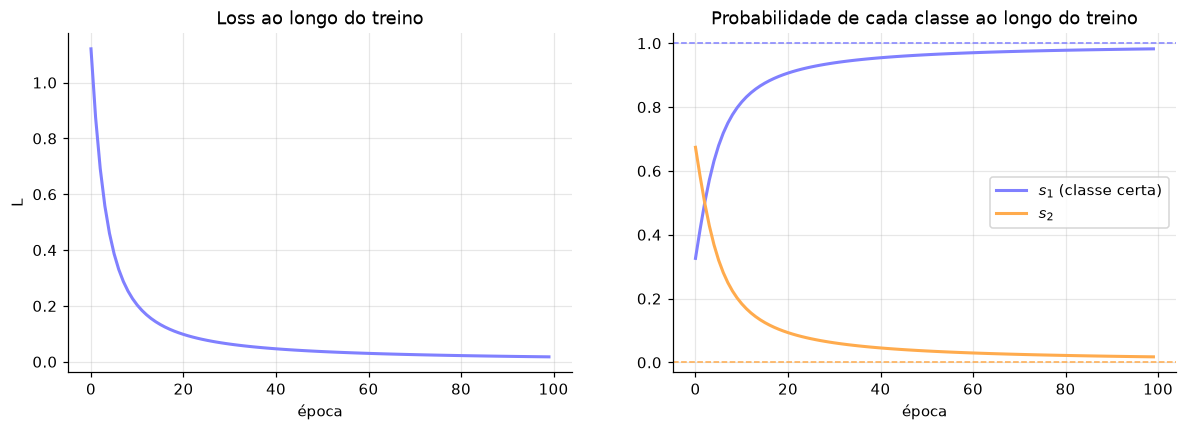

In [35]:
vis.grafico_treino(historico_L, historico_s)